In [9]:
import os

import pandas as pd
import numpy as np
from scipy.stats import genextreme, gumbel_r
import random
import itertools
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from cluster_weather_years.constants import (
    BASE_OUTPUT,
    MODELS,
    HYDROLOGICAL_YEARS,
    # NUM_CLUSTERS,
    COUNTRIES,
)

from sa_settings import MATCH_COUNTRIES, NUM_CLUSTERS

In [10]:
# RUN_ID = "20250930_1356"  # Multi-country
RUN_ID = "NL_20251104_1108"

## 1. Build dataframes

In [11]:
# build df
DF_PROD_DEMAND_FNAME = os.path.join(
    BASE_OUTPUT, "dataframes/df_prod_demand_daily_multi_country_WRONG_CAPACITIES.csv"
)
SA_OUTPUT_DIR = os.path.join(BASE_OUTPUT, "simulated_annealing")

df_daily = pd.read_csv(DF_PROD_DEMAND_FNAME, index_col=0)
df_daily["Date"] = pd.to_datetime(df_daily["Date"])
df_daily = df_daily.query("Hydrological_year > 2014 and Hydrological_year < 2044")

ALL_MATCH_COUNTRIES = ["NL", "BE", "FR", "DE"]
vars_to_match = (
    [f"{country}_OFF_prod" for country in ALL_MATCH_COUNTRIES]
    + [f"{country}_ON_prod" for country in ALL_MATCH_COUNTRIES]
    + [f"{country}_SOLAR_prod" for country in ALL_MATCH_COUNTRIES]
    + [f"{country}_Demand" for country in ALL_MATCH_COUNTRIES]
)

vars_to_standardize = vars_to_match  # df_daily.columns[3:-1].values
# df_std = standardize_df(df_daily, vars_to_standardize)

In [17]:
df_selections = pd.read_csv(
    os.path.join(SA_OUTPUT_DIR, f"run_{RUN_ID}/results_grid.csv"), index_col=0
)
df_sel_multi_country = df_selections.query(
    "optimized_metric == 'wasserstein_seasonal_score'"
).sort_values("best_score", ascending=True)

In [18]:
def build_df_centroids(df_daily, selected, mode="Hydrological_year"):
    """
    Build df with daily data of selected years
    """
    frames_centroids = []
    for i, (model, year) in enumerate(selected):
        # model_centroid, year_centroid = row["model"], row["Date"]
        if mode == "Hydrological_year":
            df_centroid = df_daily.query(
                f"model == '{model}' and Hydrological_year == {year}"
            )
        elif mode == "Calendar_year":
            df_centroid = df_daily.query(
                f"model == '{model}' and Calendar_year == {year}"
            )
        frames_centroids.append(df_centroid)

    return pd.concat(frames_centroids, ignore_index=True)


def build_df_random(df_daily, num_random=NUM_CLUSTERS):
    # build random selection df, based on random draw of NUM_CLUSTER years for comparison
    model_years = list(itertools.product(MODELS, HYDROLOGICAL_YEARS))
    random_models_years = random.sample(model_years, k=num_random)

    frames_random = []
    for model_random, year_random in random_models_years:
        df_random = df_daily.query(
            f"model == '{model_random}' and Hydrological_year == {year_random}"
        )
        frames_random.append(df_random)
    return pd.concat(frames_random, ignore_index=True)

In [19]:
columns = vars_to_standardize.copy()

# Create datasets dictionary with all available selections from df_sel_combined
datasets = {}

for i in range(len(df_sel_multi_country)):
    datasets[f"Multi-country {i + 1}"] = build_df_centroids(
        df_daily, eval(df_sel_multi_country.iloc[i]["selected"])
    )
    datasets[f"Random_N {i + 1}"] = build_df_random(df_daily, num_random=NUM_CLUSTERS)

## 2. Compute extremes

In [82]:
df_best = datasets["Multi-country 3"]  # best
# df_best.index = df_best["Date"]
df_best.reset_index(inplace=True)

df_random = datasets["Random_N 7"]  # random
# df_random.index = df_random["Date"]

for country in MATCH_COUNTRIES:
    df_best[f"{country}_wind"] = (
        df_best[f"{country}_OFF_prod"] + df_best[f"{country}_ON_prod"]
    )
    df_random[f"{country}_wind"] = (
        df_random[f"{country}_OFF_prod"] + df_random[f"{country}_ON_prod"]
    )
    df_daily[f"{country}_wind"] = (
        df_daily[f"{country}_OFF_prod"] + df_daily[f"{country}_ON_prod"]
    )

### Extreme cold week

In [74]:
import xarray as xr
import os
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [75]:
PATH = "/net/pc230050/nobackup/users/duinen/03_extremes_report/pecd_data/raw_data/2m_temperature/"
ds_temp = xr.open_dataset(
    os.path.join(
        PATH,
        "ec_earth3/P_CMI6_ECEC_ECE3_TA-_0002m_Pecd_025d_S202501010000_E202501312300_INS_MAP_01h_NA-_cdf_org_NA_SP245_NA---_NA---_PECD4.1_fv1.nc",
    )
)

In [90]:
mlz_models = ["ec_earth3", "mpi_esm1_2_hr", "cmcc_cm2_sr5"]
idxmax = df_best.query("model in @mlz_models")["NL_Demand"].idxmax()

In [100]:
model, date = df_best.loc[idxmax, ["model", "Date"]]
ds_temp_ece = xr.open_mfdataset(
    os.path.join(
        PATH,
        f"{model}/*",
    )
)

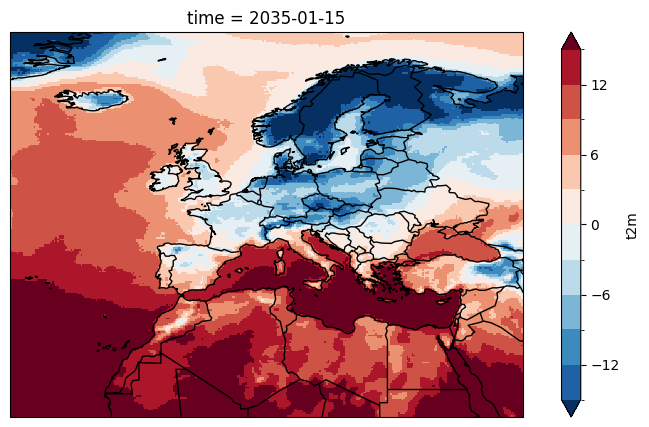

In [ ]:
fig, ax = plt.subplots(subplot_kw={"projection": ccrs.PlateCarree()}, figsize=(10, 5))
(ds_temp_ece.t2m.sel(time=date) - 273.15).plot(
    ax=ax, vmin=-15, vmax=15, levels=11, cmap="RdBu_r"
)
ax.add_feature(cfeature.BORDERS)
ax.coastlines(resolution="50m", linestyle="-", alpha=1)

### GEV-approach

In [21]:
def compute_block_maxima(df, country, var, type, window=7):
    col = f"{country}_{var}"
    grouped = df.groupby(["model", "Hydrological_year"])[col]
    if type == "max":
        yearly_max = grouped.apply(lambda g: g.rolling(window=window).mean().max())
        return sorted(yearly_max.to_numpy())
    elif type == "min":
        yearly_max = grouped.apply(lambda g: g.rolling(window=window).mean().min())
        return sorted(yearly_max.to_numpy())[::-1]


def gumbel_plot_positions(n):
    qs = (np.linspace(0, n - 1, n) + 1 - 0.3) / (n + 0.4)
    ys = -np.log(-np.log(qs))
    return np.exp(ys)


def fit_gev(block_maxima, x):
    params_gum = gumbel_r.fit(block_maxima)
    params_gev = genextreme.fit(block_maxima, loc=params_gum[0], scale=params_gum[1])
    return params_gev[0], params_gev[1] + (params_gev[2] / params_gev[0]) * (
        1 - np.exp(-params_gev[0] * np.log(x))
    )


def calc_penalty(bm, rp_emp, rp_gev, rl_gev):
    "Calculate cumulative penalty in return period direction, according to STOWA25 report Henk van den Brink."
    penalty = 0
    for i in range(len(bm)):
        idx_gev = np.argmin(np.abs(rl_gev - bm[i]))
        penalty_i = (np.log(rp_gev[idx_gev]) - np.log(rp_emp[i])) ** 2
        penalty += penalty_i
    return penalty


country = "NL"
var = "Demand"
type = "max"  # use max for demand variables, min for production variables
window = 7


def extremes_comparison(country, var, type="max", window=7, plot=True):
    # compute block maxima
    bm_best = compute_block_maxima(df_best, country, var, type, window)
    bm_random = compute_block_maxima(df_random, country, var, type, window)
    bm_full = compute_block_maxima(df_daily, country, var, type, window)

    # fit gev
    rp_gev = np.logspace(np.log10(1e-1), np.log10(1e3), 1000)
    if type == "max":
        _, rl_gev = fit_gev(bm_full, rp_gev)

    elif type == "min":
        bm_full_fit = [-x for x in bm_full]
        _, rl_gev_neg = fit_gev(bm_full_fit, rp_gev)
        rl_gev = [-x for x in rl_gev_neg]

    # calc plot positions
    rp_full = gumbel_plot_positions(len(bm_full))
    rp_random = gumbel_plot_positions(len(bm_random))
    rp_best = gumbel_plot_positions(len(bm_best))

    if plot:
        # plot
        plt.figure()
        plt.plot(rp_gev, rl_gev, label="GEV Full", color="C0")
        plt.scatter(rp_full, bm_full, label="Full (empirical)")
        plt.scatter(rp_random, bm_random, label="Random")
        plt.scatter(rp_best, bm_best, label="Best")
        plt.xscale("log")
        plt.xlabel("Return period (years)")
        plt.ylabel("Return value (GWh/day)")
        plt.title(f"{country} {var} block {type} ({window}-day rolling mean)")
        plt.legend()

    # calculate penalties
    dist_random = calc_penalty(bm_random, rp_random, rp_gev, rl_gev)
    dist_best = calc_penalty(bm_best, rp_best, rp_gev, rl_gev)
    # print(f"Penalty random: {dist_random:.2f}, best: {dist_best:.2f}")
    return dist_best, dist_random

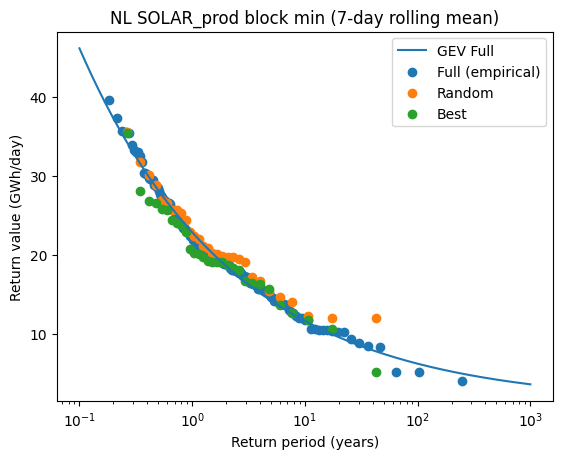

In [22]:
# Quick test with fitting gev on minima

var = "SOLAR_prod"
type = "min"
plot = True
bm_best = compute_block_maxima(df_best, country, var, type, window)
bm_random = compute_block_maxima(df_random, country, var, type, window)
bm_full = compute_block_maxima(df_daily, country, var, type, window)

# fit gev
rp_gev = np.logspace(np.log10(1e-1), np.log10(1e3), 1000)
_, rl_gev = fit_gev(-np.array(bm_full), rp_gev)

# calc plot positions
rp_full = gumbel_plot_positions(len(bm_full))
rp_random = gumbel_plot_positions(len(bm_random))
rp_best = gumbel_plot_positions(len(bm_best))

if plot:
    # plot
    plt.figure()
    plt.plot(rp_gev, -rl_gev, label="GEV Full", color="C0")
    plt.scatter(rp_full, bm_full, label="Full (empirical)")
    plt.scatter(rp_random, bm_random, label="Random")
    plt.scatter(rp_best, bm_best, label="Best")
    plt.xscale("log")
    plt.xlabel("Return period (years)")
    plt.ylabel("Return value (GWh/day)")
    plt.title(f"{country} {var} block {type} ({window}-day rolling mean)")
    plt.legend()

dist_random = calc_penalty(bm_random, rp_random, rp_gev, -rl_gev)
dist_best = calc_penalty(bm_best, rp_best, rp_gev, -rl_gev)

Random summed distance: 8.64, best: 8.41


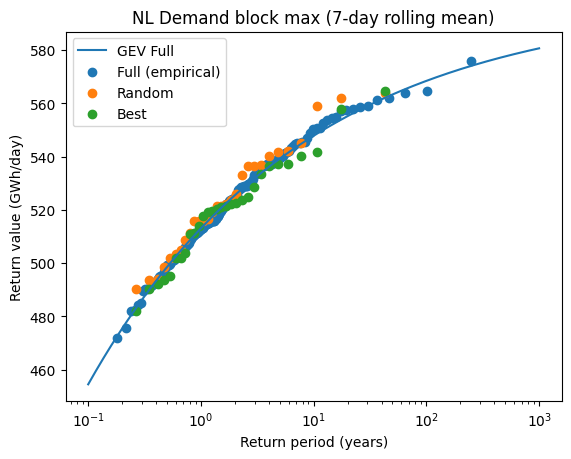

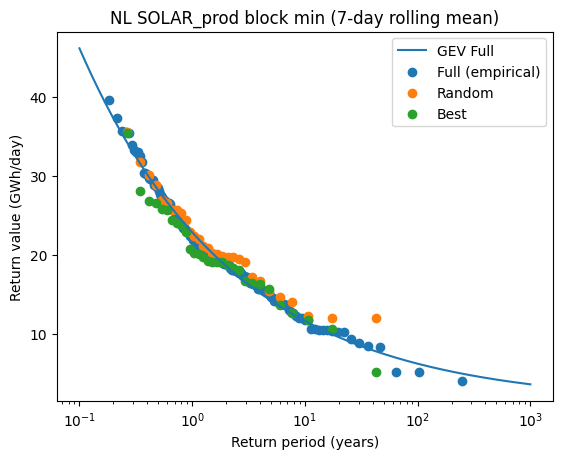

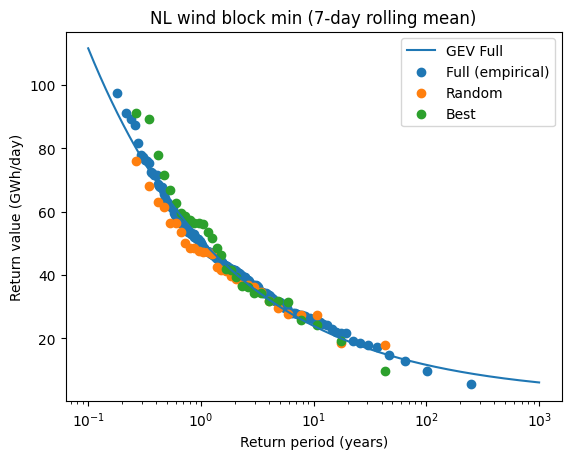

In [23]:
country = "NL"
vars = ["Demand", "SOLAR_prod", "wind"]
types = ["max", "min", "min"]
dist_best_list = []
dist_random_list = []
for var, type in zip(vars, types):
    dist_best, dist_random = extremes_comparison(
        country, var, type=type, window=7, plot=True
    )
    dist_best_list.append(dist_best)
    dist_random_list.append(dist_random)
dist_random_list, dist_best_list
print(
    f"Random summed distance: {sum(dist_random_list):.2f}, best: {sum(dist_best_list):.2f}"
)

In [24]:
def horizontal_distances(emp_rp, emp_rl, rp_curve, rl_curve):
    """
    For each empirical (emp_rp, emp_rl), return |emp_rp - rp_gev(emp_rl)|.
    rp_gev(emp_rl) is obtained by inverting the GEV curve via interpolation.
    """
    order = np.argsort(rl_curve)
    rl_sorted = np.asarray(rl_curve)[order]
    rp_sorted = np.asarray(rp_curve)[order]
    rp_on_gev = np.interp(emp_rl, rl_sorted, rp_sorted)
    return np.abs(np.asarray(emp_rp) - rp_on_gev), rp_on_gev


# Horizontal deviations (years) to GEV curve
dist_full, _ = horizontal_distances(rp_full, bm_full, rp_gev, rl_gev)
dist_random, _ = horizontal_distances(rp_random, bm_random, rp_gev, rl_gev)
dist_best, _ = horizontal_distances(rp_best, bm_best, rp_gev, rl_gev)

In [25]:
dist_full.sum(), dist_random.sum(), dist_best.sum()

(172987.6772652544, 29876.587052448856, 29876.587052448856)